# ncvgbdt: a full example

This notebook walks through the whole workflow on a small **synthetic** data set
(so no data files are needed):

1. data with repeated measures, a country level, missing values and all predictor types,
2. a regression with nested cross-validation, grouped by participant,
3. scores against a shuffled-target baseline, and predictor effects with p values
   (also corrected for multiple comparisons) and SHAP values, all as tables,
4. figures that you can edit and save,
5. SHAP interaction values (figure and table),
6. a classification of the same data,
7. choosing the grouping unit (participants vs. countries),
8. a final model for predictions, and saving / loading everything.

The settings are small so that it runs in a few minutes. For real analyses use the
defaults (e.g. `n_rep_outer_cv=10`, `n_samples_rs=100`) or larger values, see
`help(NCVGBDTRegressor)`.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ncvgbdt import (NCVGBDTClassifier, NCVGBDTRegressor, load_model,
                     make_figures, save_figures)

plt.ioff()  # figures are shown only when we display them ourselves
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

@contextlib.contextmanager
def quiet():
    # fit() prints a progress log (tuned parameters and running scores per fold).
    # It is hidden here to keep the notebook short: remove `with quiet():` to see it.
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield


OUT = Path("example_output")  # everything is stored here (ignored by git)
# quick settings for this demo; the defaults are meant for real analyses
FAST = dict(n_rep_outer_cv=1, n_samples_inner_cv=500, n_samples_rs=10,
            max_samples_shap=60)

C:\imltools\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

300 participants in 12 countries, each measured twice (600 rows). Wellbeing depends on
trust, income (log), age (U-shaped), living in a city and education; countries and
participants have their own offsets, which is why rows of the same participant are
**not independent**. Some `income` and `trust` values are missing.

In [2]:
def make_data(seed=42):
    rng = np.random.default_rng(seed)
    n_countries, per_country, n_meas = 12, 25, 2
    n_part = n_countries * per_country
    country_of = np.repeat(np.arange(n_countries), per_country)
    codes = np.array(["AT", "BR", "CN", "DE", "EG", "FR", "IN", "JP", "KE", "MX", "NO", "US"])

    age = rng.uniform(18, 80, n_part)
    income = rng.lognormal(mean=10.5, sigma=0.5, size=n_part)
    urban = rng.integers(0, 2, n_part)
    education = rng.choice(["primary", "secondary", "bachelor", "master", "phd"],
                           size=n_part, p=[.15, .35, .3, .15, .05])
    trust_mean = rng.normal(0, 1, n_part)
    edu_effect = {"primary": -.4, "secondary": -.1, "bachelor": .2, "master": .4, "phd": .5}
    country_effect = rng.normal(0, .5, n_countries)
    part_effect = rng.normal(0, .7, n_part)

    rows = []
    for i in range(n_part):
        for _ in range(n_meas):
            trust = trust_mean[i] + rng.normal(0, .4)
            wellbeing = (5 + 0.8 * trust
                         + 0.5 * (np.log(income[i]) - 10.5)
                         - 0.0006 * (age[i] - 50) ** 2
                         + 0.3 * urban[i] + edu_effect[education[i]]
                         + country_effect[country_of[i]] + part_effect[i]
                         + rng.normal(0, .6))
            rows.append((i, codes[country_of[i]], age[i], income[i], trust,
                         urban[i], education[i], wellbeing))
    df = pd.DataFrame(rows, columns=["participant", "country", "age", "income", "trust",
                                     "urban", "education", "wellbeing"])
    # a binary version of the target
    df["above_median"] = (df["wellbeing"] > df["wellbeing"].median()).astype(int)
    # missing values: income more often for older people, trust at random
    miss_income = rng.random(len(df)) < 0.04 + 0.12 * (df["age"] > 60)
    miss_trust = rng.random(len(df)) < 0.06
    df.loc[miss_income, "income"] = np.nan
    df.loc[miss_trust, "trust"] = np.nan
    return df


df = make_data()
print(df.shape)
df.head()

(600, 9)


,participant,country,age,income,trust,urban,education,wellbeing,above_median
0,0,AT,65.985275,31379.635392,-2.176897,1,secondary,5.153842,1
1,0,AT,65.985275,31379.635392,-2.768656,1,secondary,5.104533,1
2,1,AT,45.210463,34484.177201,-0.929583,1,primary,4.502538,0
3,1,AT,45.210463,34484.177201,-0.560782,1,primary,4.440617,0
4,2,AT,71.233071,NaN,-0.052301,0,primary,4.514331,0


In [3]:
df.isna().sum()[["income", "trust"]]

income    57
trust     26
dtype: int64

## 2. A regression, grouped by participant

* `x_con_names`: continuous predictors, `x_cat_bin_names`: binary predictors coded 0/1,
  `x_cat_mult_names`: categorical predictors with more than two levels (target encoded
  inside the cross-validation, so nothing leaks from the test folds).
* `groups='participant'` keeps all rows of a participant on the same side of every split.
  Without it, one person's rows could be in the training *and* the test set and the
  performance would be inflated.
* **Missing predictor values** are kept by default (`missing='native'`): LightGBM handles
  them. Use `missing='drop'` to remove such rows instead.
* `refit=True` additionally fits one final model on all rows (used in section 8).
* `output_dir` stores every outer fold as JSON while fitting, so an interrupted run can be
  continued with `resume=True`.

`fit` prints a progress log; the `quiet()` helper above hides it here.

In [4]:
model = NCVGBDTRegressor(
    x_con_names=["age", "income", "trust"],
    x_cat_bin_names=["urban"],
    x_cat_mult_names=["education"],
    evaluation="CV",
    shap_interactions=True,
    refit=True,
    output_dir=OUT / "wellbeing",
    **FAST,
)
with quiet():
    model.fit(df, "wellbeing", groups="participant")
print("rows used:", model.n_samples_used_, "of", len(df))

rows used: 600 of 600


## 3. Scores and effect sizes

`cv_results_` has one row per outer fold. Every score is also computed for a model fitted on
**shuffled targets** (`*_shuffled`): that is what the model achieves when predictors and target
are unrelated, the reference to compare against.

In [5]:
model.cv_results_[["fold", "r2", "r2_shuffled", "rmse", "rmse_shuffled"]].round(3)

,fold,r2,r2_shuffled,rmse,rmse_shuffled
0,0,0.440,0.077,1.102,1.416
1,1,0.458,-0.004,1.265,1.722
2,2,0.436,0.016,0.995,1.313
3,3,0.485,-0.031,1.016,1.437
4,4,0.334,-0.025,1.150,1.426


In [6]:
model.scores_summary_.round(3)

,mean,sd,ci_low,ci_high,mean_shuffled,sd_shuffled,p_value
metric,,,,,,,
r2,0.430,0.057,0.323,0.537,0.007,0.043,0.000
mae,0.888,0.082,0.734,1.042,1.161,0.111,0.001
mse,1.232,0.247,0.772,1.692,2.158,0.472,0.004
rmse,1.106,0.109,0.902,1.309,1.463,0.153,0.001


`scores_summary_` gives mean, sd, an approximate 95 % interval and a one-sided p value of the
model against the shuffled baseline (corrected resampled t-test; folds of repeated CV are not
independent, so treat the p values as approximate, see the README).

Everything below is a plain table: you do not need to draw figures to get the numbers.

### Effects of the predictors

`effect_sizes_` describes each predictor: `effect` is the mean absolute SHAP value (in units of
the target) with an approximate interval, `effect_share` its percentage of the total and
`effect_shuffled` the effect without any real relation, the reference to compare with.

In [7]:
es = model.effect_sizes_
es[["feature", "effect", "effect_ci_low", "effect_ci_high", "effect_share",
    "effect_shuffled"]].round(3)

,feature,effect,effect_ci_low,effect_ci_high,effect_share,effect_shuffled
0,age,0.059,-0.014,0.132,3.941,0.057
1,income,0.183,0.100,0.266,12.752,0.087
2,trust,0.701,0.603,0.800,49.393,0.076
3,urban,0.283,0.225,0.341,19.840,0.073
4,education,0.203,0.119,0.287,14.075,0.081


`p_value` tests whether a predictor's effect is larger than its effect in the shuffled-target
model (over the outer folds). Many predictors are tested at once, so there are adjusted versions
too: `p_value_bonferroni` (p times the number of predictors, the most conservative),
`p_value_holm` (step-down, never less powerful than Bonferroni) and `p_value_fdr_bh`
(Benjamini-Hochberg false discovery rate, the least conservative). The figures print these same
values.

In [8]:
es[["feature", "p_value", "p_value_bonferroni", "p_value_holm", "p_value_fdr_bh"]].round(4)

,feature,p_value,p_value_bonferroni,p_value_holm,p_value_fdr_bh
0,age,0.4616,1.0000,0.4616,0.4616
1,income,0.0087,0.0436,0.0261,0.0145
2,trust,0.0000,0.0001,0.0001,0.0001
3,urban,0.0004,0.0022,0.0018,0.0011
4,education,0.0234,0.1168,0.0467,0.0292


`slope_per_sd` and `corr_x_shap` give the direction: the change of the prediction per +1 SD of
the predictor and the correlation between predictor values and their SHAP values (both are
undefined for the multi-category `education`, which has no order).

In [9]:
es[["feature", "slope_per_sd", "slope_ci_low", "slope_ci_high", "corr_x_shap"]].round(3)

,feature,slope_per_sd,slope_ci_low,slope_ci_high,corr_x_shap
0,age,0.035,0.005,0.065,0.615
1,income,0.166,0.107,0.225,0.784
2,trust,0.763,0.663,0.862,0.956
3,urban,0.278,0.212,0.343,0.992
4,education,NaN,NaN,NaN,NaN


### SHAP values as tables

`shap_values_` holds the SHAP value of every explained test row, feature and fold in long format,
and `shap_explanation()` returns the same pooled over the folds as one `shap.Explanation` for your
own SHAP plots. Here is a plot made from the table alone:

In [10]:
sv = model.shap_values_
sv.head()

,fold,row,class,feature,feature_value,shap_value
0,0,0,None,age,26.664654,-0.049904
1,0,0,None,income,42446.712122,0.178147
2,0,0,None,trust,0.31462,0.429853
3,0,0,None,urban,0,-0.252964
4,0,0,None,education,primary,-0.275262


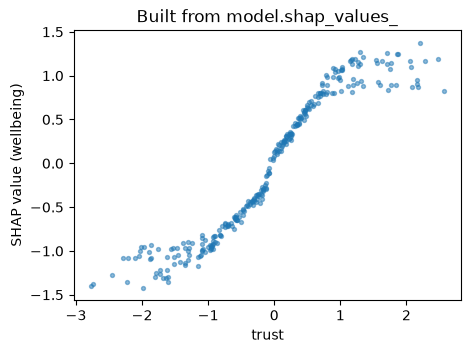

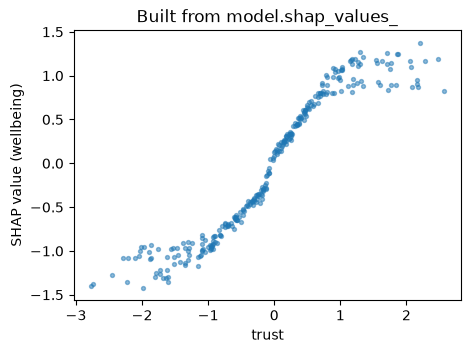

In [11]:
trust = sv[sv["feature"] == "trust"]
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(trust["feature_value"], trust["shap_value"], s=8, alpha=0.5)
ax.set(xlabel="trust", ylabel="SHAP value (wellbeing)", title="Built from model.shap_values_")
fig

In [12]:
ex = model.shap_explanation()   # pooled over the folds
print(ex.values.shape, ex.feature_names)

(300, 5) ['age', 'income', 'trust', 'urban', 'education']


## 4. Figures you can edit

`make_figures` returns `{name: (fig, ax)}` and writes nothing unless you pass `output_dir`.
`plot_type` chooses the figures (default: `fit`, `shap_effects`, `shap_effects_distribution`,
`shap_values`); `"dependence"` and the interaction types create one figure per predictor or pair.

C:\imltools\.venv\Lib\site-packages\shap\plots\_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


['fit_scatter',
 'fit_violin',
 'shap_effects',
 'shap_values',
 'dependence:age',
 'dependence:income',
 'dependence:trust',
 'dependence:urban',
 'dependence:education']

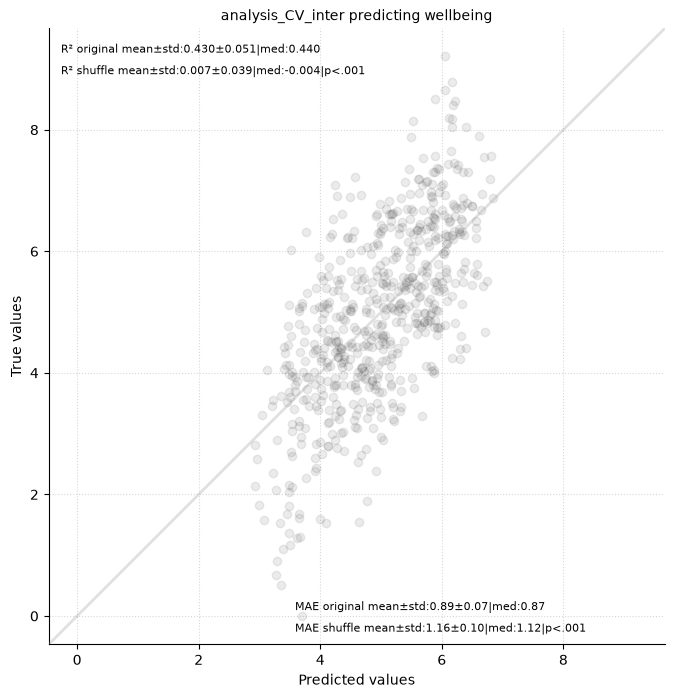

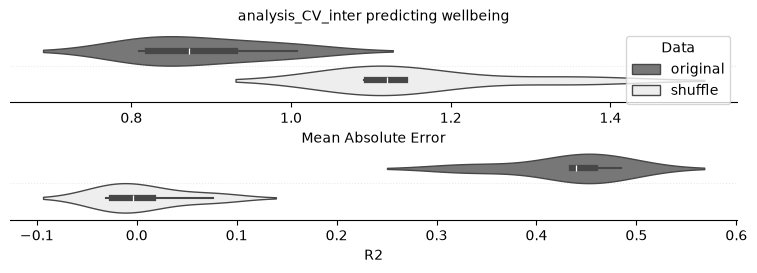

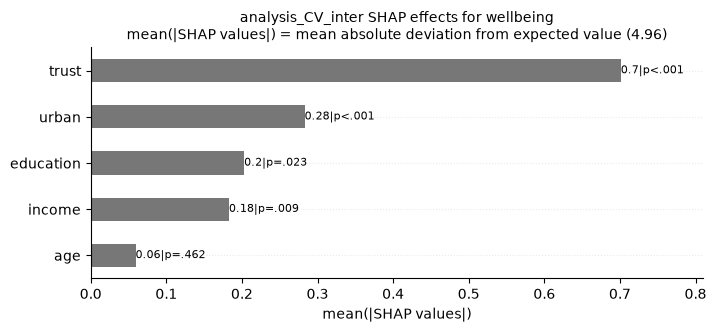

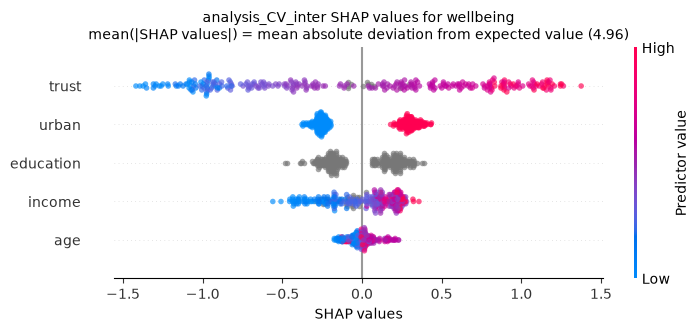

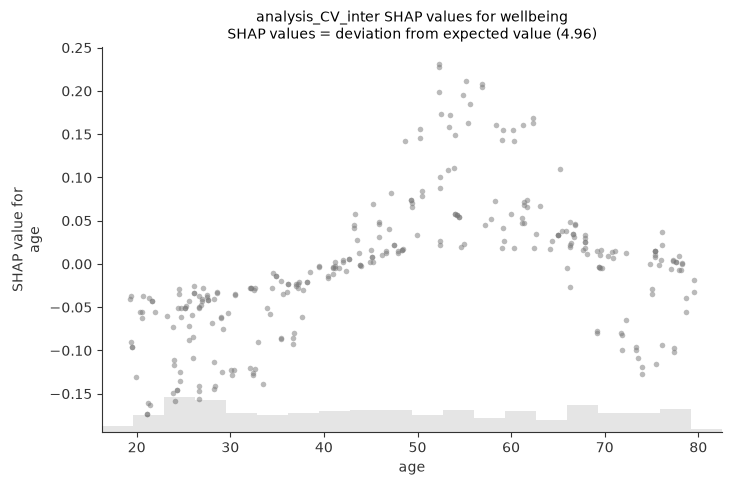

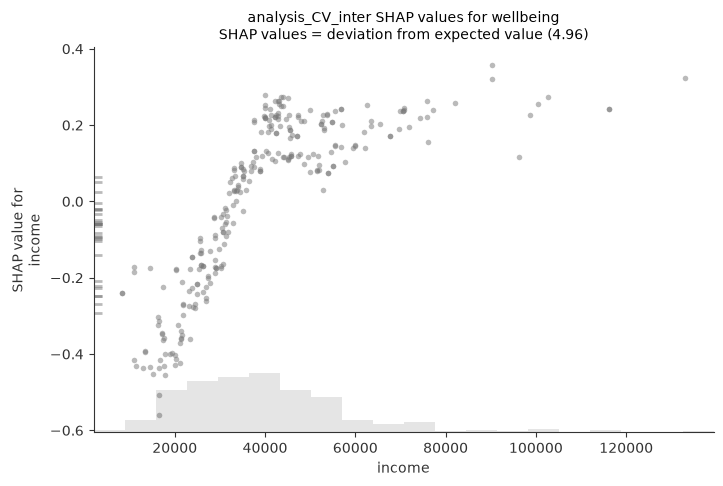

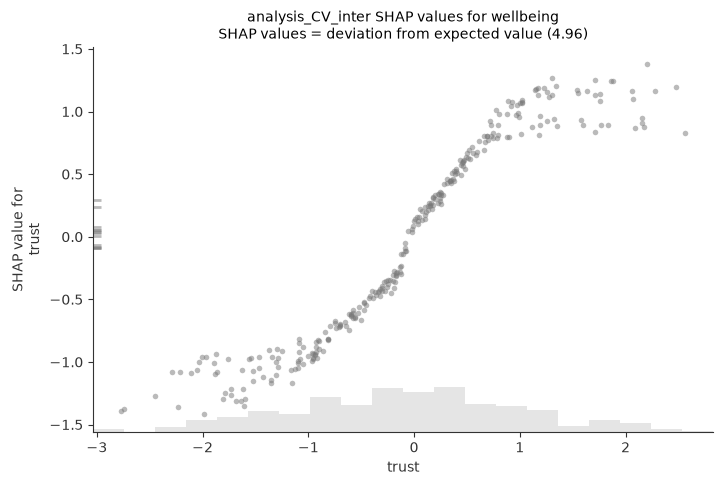

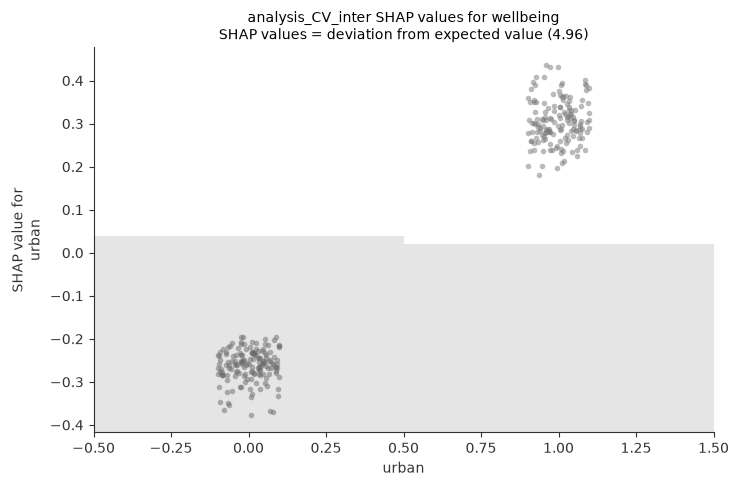

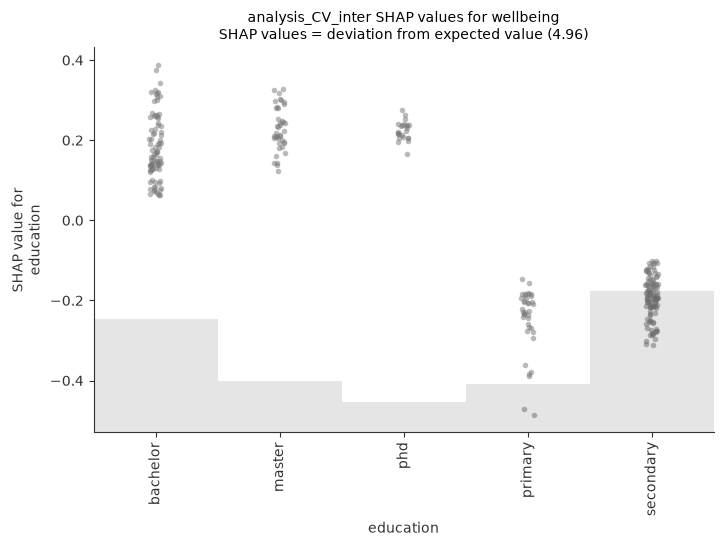

In [13]:
figs = make_figures(model, plot_type=["fit", "shap_effects", "shap_values", "dependence"])
list(figs)

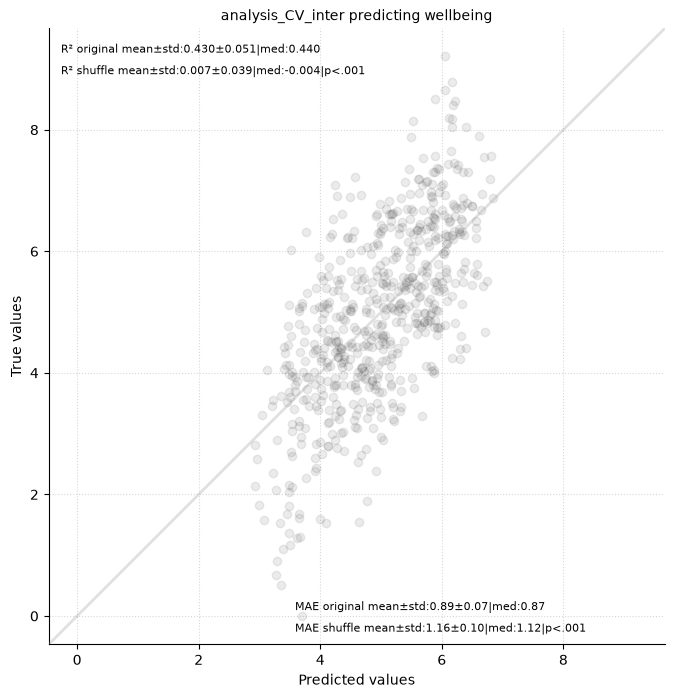

In [14]:
figs["fit_scatter"][0]

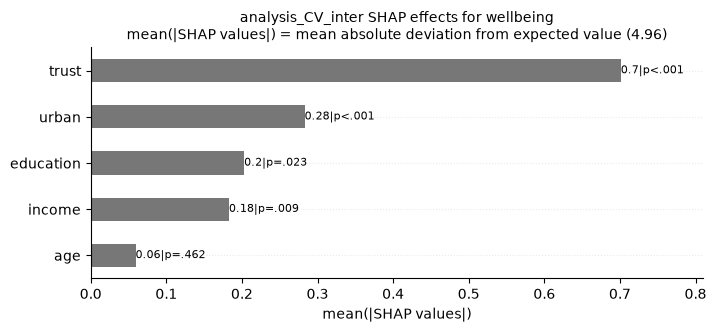

In [15]:
figs["shap_effects"][0]

The p values printed in this figure are the `p_value` column of `effect_sizes_`. Choose a
correction with `multiple_comparison_correction` (`None`, `'bonferroni'`, `'holm'` or `'fdr_bh'`):

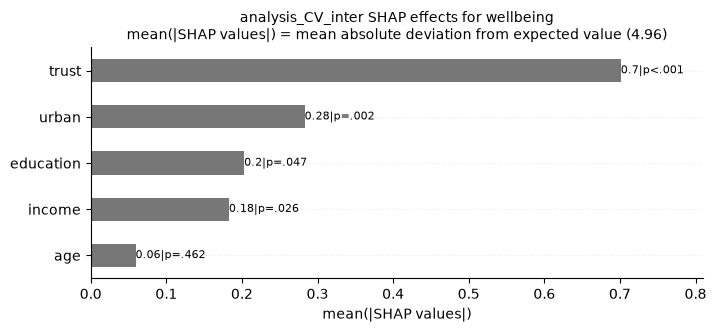

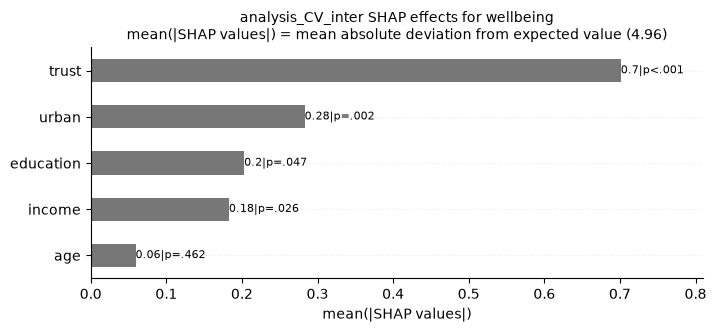

In [16]:
holm = make_figures(model, plot_type="shap_effects", multiple_comparison_correction="holm")
holm["shap_effects"][0]

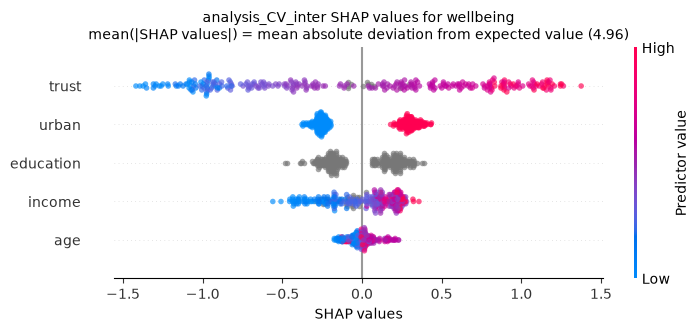

In [17]:
figs["shap_values"][0]

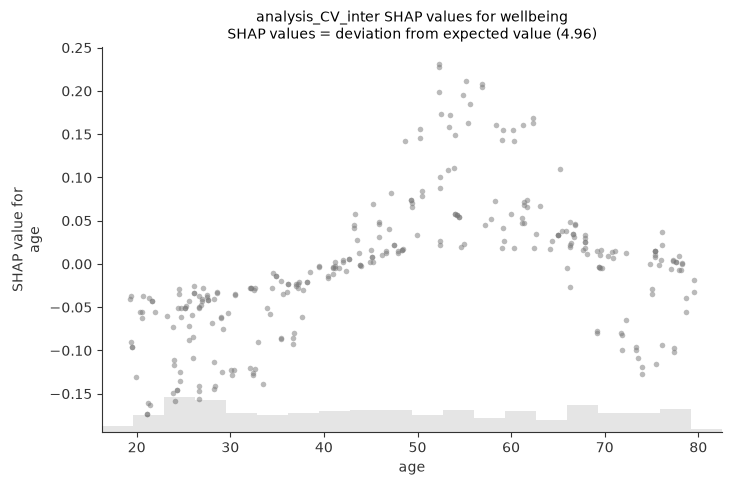

In [18]:
figs["dependence:age"][0]

Edit any figure through the returned objects, then save the edited figures with `save_figures`
(`png`, `svg` or `pdf`; `dpi` applies to PNG).

18 files, e.g. ['fit_scatter.png', 'fit_scatter.pdf', 'fit_violin.png', 'fit_violin.pdf']


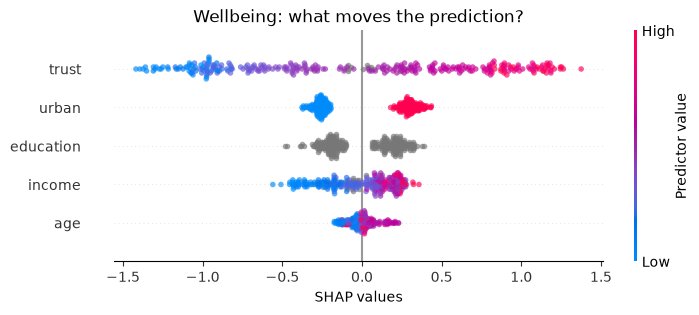

In [19]:
fig, ax = figs["shap_values"]
ax.set_title("Wellbeing: what moves the prediction?", fontsize=12)

files = save_figures(figs, OUT / "figures", fig_format=["png", "pdf"], dpi=200)
print(len(files), "files, e.g.", [Path(f).name for f in files[:4]])
fig

## 5. SHAP interaction values

The model was fitted with `shap_interactions=True`, so the interaction figures and the table `interaction_effects_` are
available. The figures are drawn per ordered pair of predictors, so pick what you need.

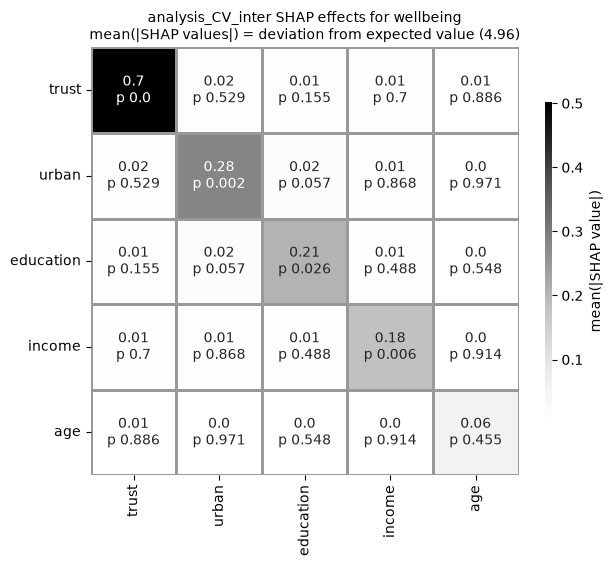

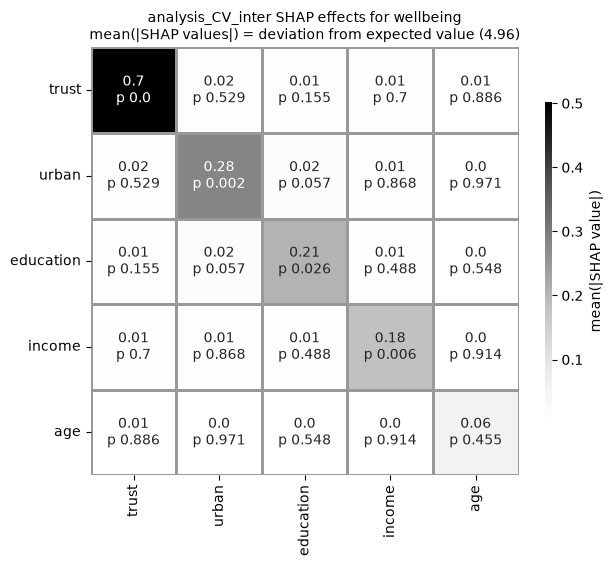

In [20]:
inter = make_figures(model, plot_type=["interaction_effects"])
inter["interaction_effects"][0]

The same numbers as a table, one row per cell of the predictor matrix. The matrix is symmetric, so
keep each pair once; the p values are adjusted over all cells.

In [21]:
ie = model.interaction_effects_
pairs = ie[ie["feature_a"] < ie["feature_b"]]
pairs.sort_values("effect", ascending=False).head(5)[
    ["feature_a", "feature_b", "effect", "effect_shuffled", "p_value", "p_value_holm"]
].round(3)

,feature_a,feature_b,effect,effect_shuffled,p_value,p_value_holm
23,education,urban,0.020,0.011,0.057,1.0
13,trust,urban,0.016,0.016,0.529,1.0
22,education,trust,0.013,0.010,0.155,1.0
8,income,urban,0.012,0.021,0.868,1.0
7,income,trust,0.011,0.016,0.700,1.0


## 6. A classification of the same data

`NCVGBDTClassifier` takes any labels; two classes are fitted as binary, three or more as
multiclass. Performance is the **balanced accuracy** (and AUC, log loss, pseudo R2, ... in
`scores_summary_`); the probability based metrics are class-balanced, see the README.

In [22]:
clf = NCVGBDTClassifier(
    x_con_names=["age", "income", "trust"],
    x_cat_bin_names=["urban"],
    x_cat_mult_names=["education"],
    shap_interactions=False,
    **FAST,
)
with quiet():
    clf.fit(df, "above_median", groups="participant")
clf.scores_summary_.loc[["acc", "auc", "logloss", "mcfadden", "tjur"]].round(3)

,mean,sd,ci_low,ci_high,mean_shuffled,sd_shuffled,p_value
metric,,,,,,,
acc,0.738,0.050,0.646,0.831,0.545,0.052,0.003
auc,0.798,0.036,0.732,0.865,0.556,0.059,0.001
logloss,0.555,0.036,0.487,0.623,0.689,0.016,0.001
mcfadden,0.199,0.053,0.101,0.297,0.007,0.023,0.001
tjur,0.249,0.031,0.191,0.308,0.018,0.024,0.000


In [23]:
clf.effect_sizes_[["feature", "class", "effect", "effect_shuffled", "p_value",
                   "p_value_holm"]].round(3)

,feature,class,effect,effect_shuffled,p_value,p_value_holm
0,age,1,0.107,0.097,0.384,0.384
1,income,1,0.257,0.132,0.021,0.064
2,trust,1,0.907,0.125,0.000,0.001
3,urban,1,0.278,0.101,0.025,0.064
4,education,1,0.297,0.086,0.005,0.020


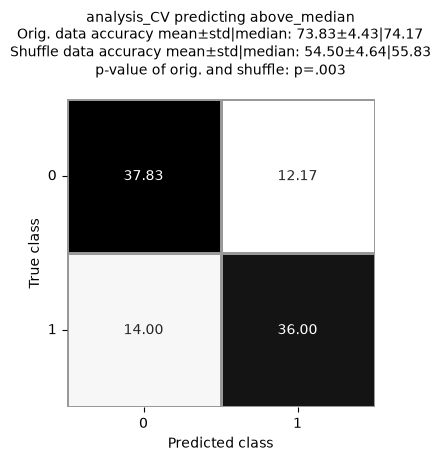

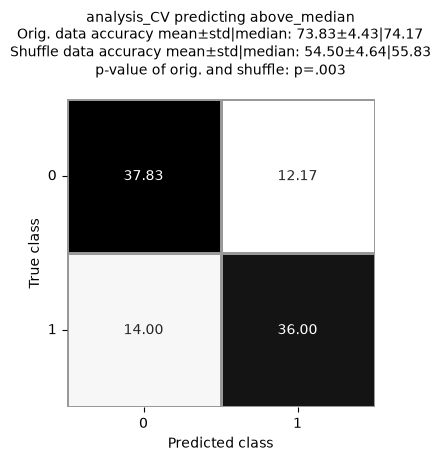

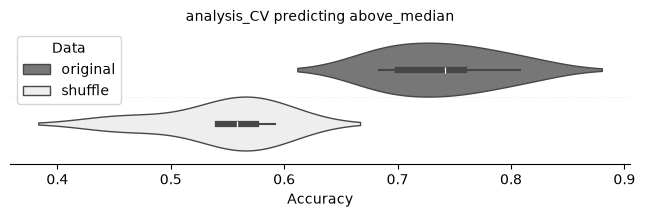

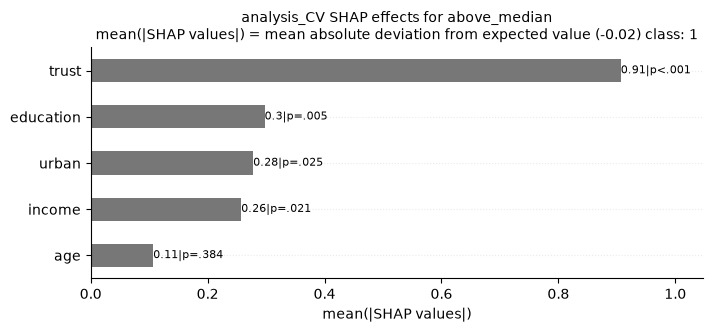

In [24]:
clf_figs = make_figures(clf, plot_type=["fit", "shap_effects"], classes=[1])
clf_figs["fit_confusion"][0]

## 7. Which unit should `groups` be?

The group is the unit the model is **tested on**:

* `groups="participant"`: how well does the model predict *new people*?
* `groups="country"`: how well does it predict people from *countries it has never seen*?
  This is stricter. Do not use the country as a predictor in that case: every test country is
  unseen, so its category carries no information.

In [25]:
by_country = NCVGBDTRegressor(
    x_con_names=["age", "income", "trust"],
    x_cat_bin_names=["urban"],
    x_cat_mult_names=["education"],
    shap_interactions=False,
    **FAST,
)
with quiet():
    by_country.fit(df, "wellbeing", groups="country")

pd.DataFrame({
    "new people (groups=participant)": [model.score_, model.score_shuffled_],
    "new countries (groups=country)": [by_country.score_, by_country.score_shuffled_],
}, index=["R2 of the model", "R2 of the shuffled baseline"]).round(3)

,new people (groups=participant),new countries (groups=country)
R2 of the model,0.430,0.376
R2 of the shuffled baseline,0.007,-0.056


## 8. The final model, saving and loading

With `refit=True` the estimator offers `predict`, `explain` and (classifier) `predict_proba` for
new data. Its quality is the one estimated by the outer folds above; it is not evaluated itself.
Rows with missing values are fine.

In [26]:
new = df.sample(5, random_state=1).drop(columns=["wellbeing"])
pd.DataFrame({"predicted": model.predict(new).round(2),
              "income": new["income"].to_numpy()}, index=new.index)

,predicted,income
446,3.13,31298.902708
404,5.04,NaN
509,5.91,41102.858607
455,4.42,43145.034437
201,6.55,41695.024731


In [27]:
exp = model.explain(new)               # shap.Explanation
# the model was fitted with shap_interactions=True: values are (rows, features, features)
main = exp.values.sum(axis=2)          # main SHAP value per row and predictor
dict(zip(exp.feature_names, np.abs(main).mean(axis=0).round(3)))

{'age': np.float64(0.101),
 'income': np.float64(0.161),
 'trust': np.float64(0.885),
 'urban': np.float64(0.279),
 'education': np.float64(0.217)}

Everything was stored in `OUT / "wellbeing"` as JSON (plus `final_model.joblib` for the final
model), so you can reload it later, in another session:

```python
model = load_model("example_output/wellbeing")
```

An interrupted fit can be continued with the same data and settings:

```python
NCVGBDTRegressor(..., output_dir="example_output/wellbeing", resume=True).fit(df, "wellbeing", groups="participant")
```

In [28]:
loaded = load_model(OUT / "wellbeing")
print("same scores after loading:", loaded.cv_results_.equals(model.cv_results_))
print("same predictions:", np.allclose(loaded.predict(new), model.predict(new)))
sorted(p.name for p in (OUT / "wellbeing").iterdir())

same scores after loading: True
same predictions: True


['final_model.joblib', 'folds', 'manifest.json']

In [29]:
plt.close("all")   # figures stay open until you close them